Nucleos disponibles: 12   N_NUCLEOS = -1
Conservadores eligen 2 en: 022, 122, 202, 212, 220, 221, 222
Agresivos     eligen 1 en: 011, 101, 110, 111, 112, 121, 211
Fracciones (de cada tipo): ['0%', '5%', '10%', '15%', '20%']   semillas por punto: 100

  GRUPO1: N = [50, 100, 200, 300]

  N = 50  (alfa = 27/50 = 0.5400)  listo en 26.5 s
       %       c+a    f(0)    f(1)    f(2)  h>1dos  h>1unos  exito tot    cons     agr  comunes       M(1)
       0       0+0  0.3347  0.3305  0.3348  0.2602   0.2594     0.2926     nan     nan   0.2926  2.575e-02
       5       3+3  0.3676  0.3136  0.3188  0.2258   0.2252     0.2927  0.2755  0.2768   0.2950  3.452e-02
      10       5+5  0.3783  0.3073  0.3143  0.2138   0.2092     0.2909  0.2642  0.2623   0.2978  4.349e-02
      15       8+8  0.3860  0.3039  0.3101  0.2016   0.1982     0.2868  0.2519  0.2513   0.3033  6.059e-02
      20     10+10  0.3931  0.3005  0.3064  0.1941   0.1919     0.2833  0.2496  0.2495   0.3058  5.947e-02

  N = 100  (alfa = 2

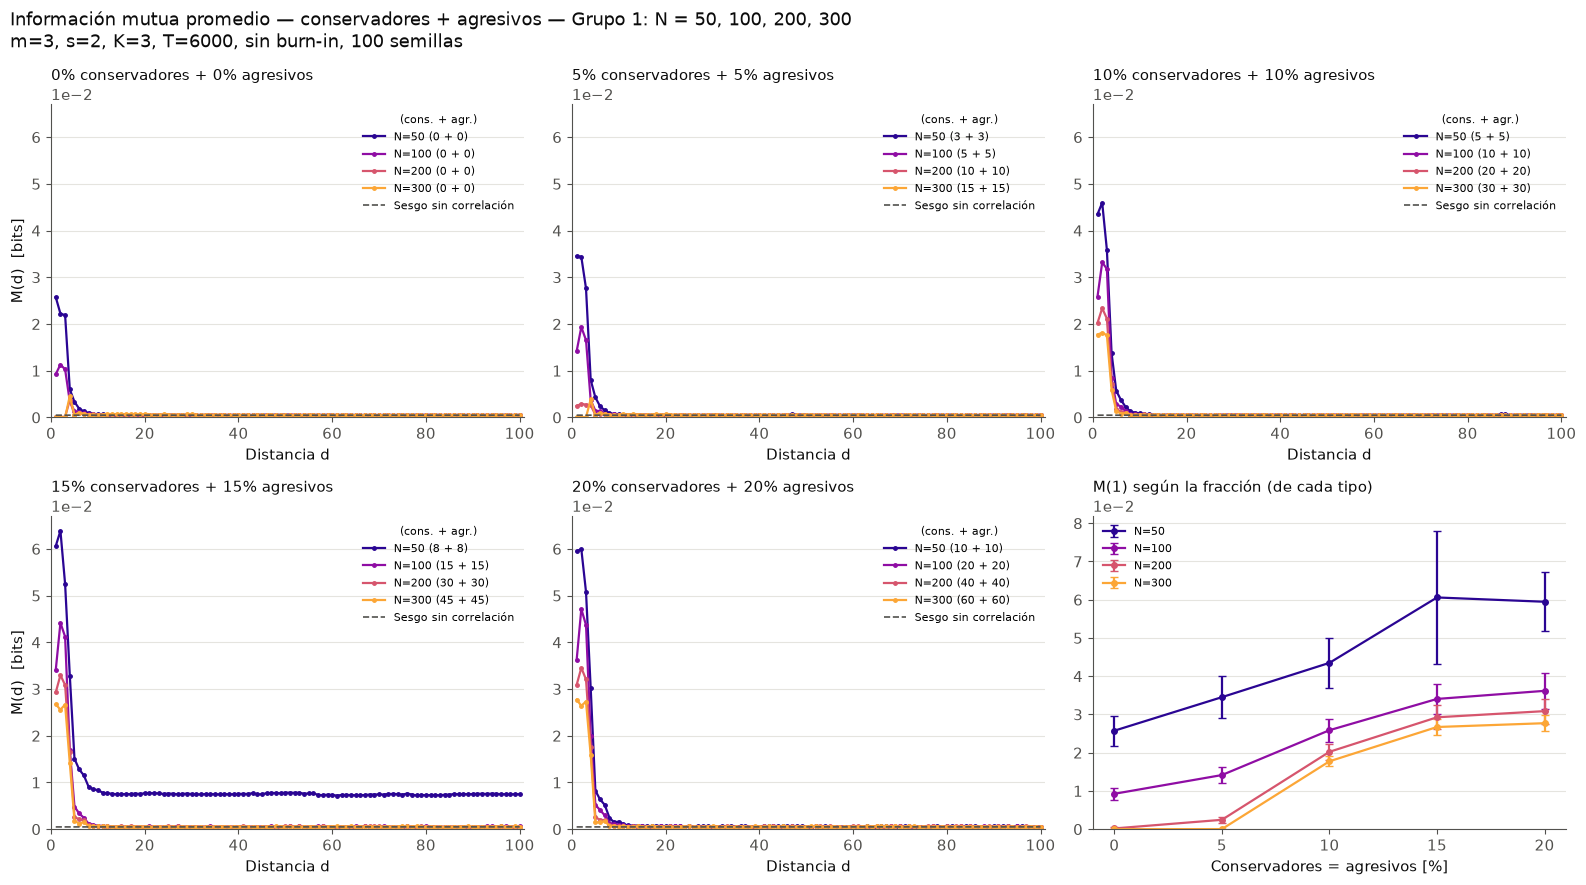

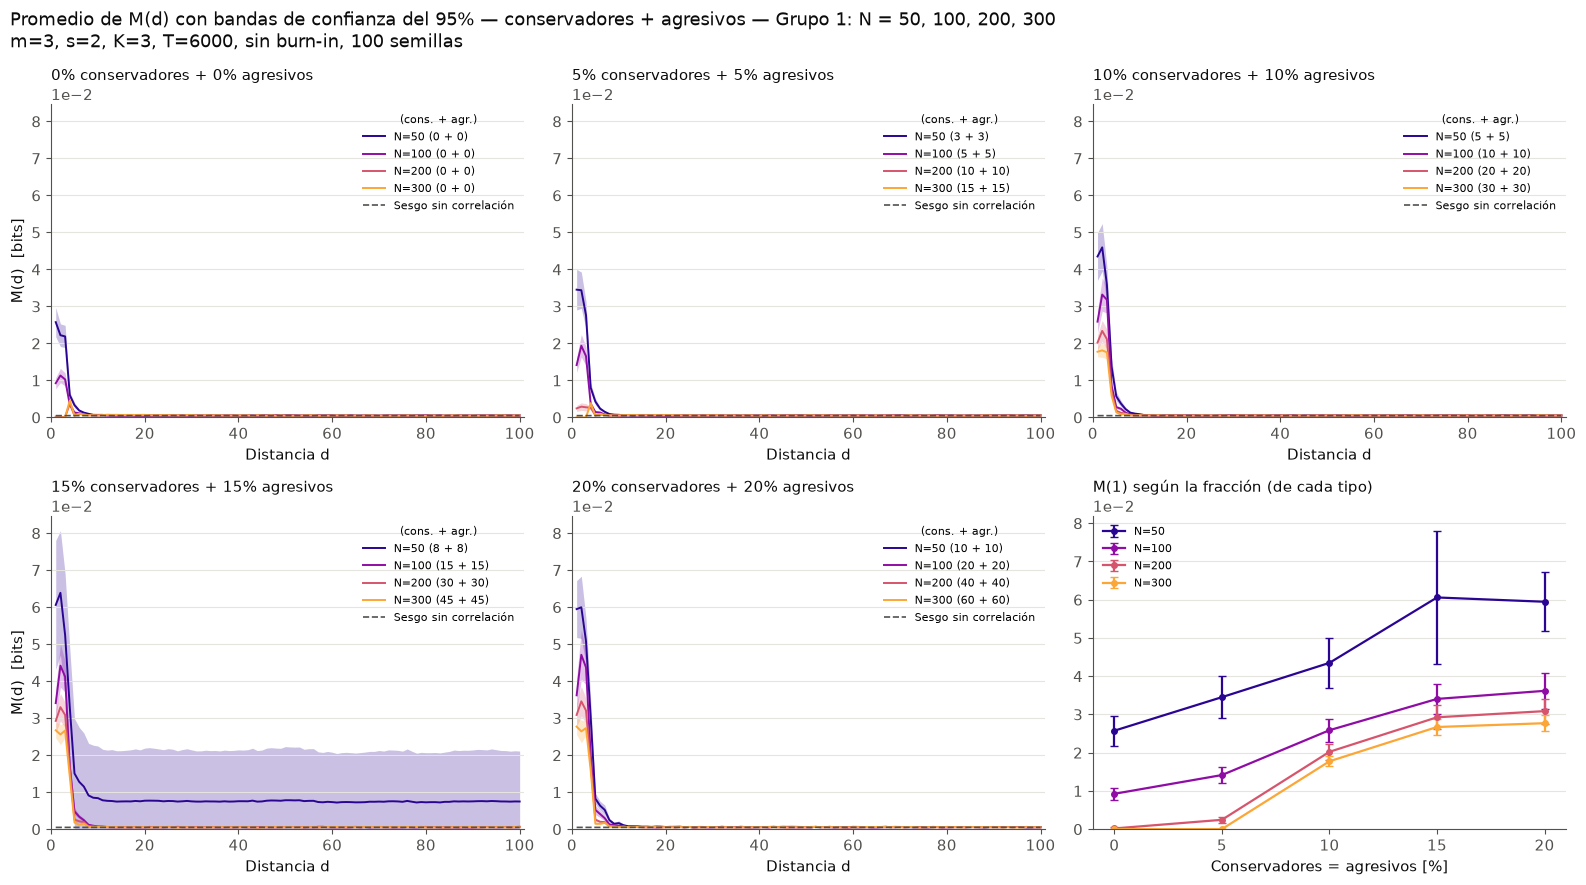


  GRUPO2: N = [1000, 2000, 3000, 4000]

  N = 1000  (alfa = 27/1000 = 0.0270)  listo en 41.8 s
       %       c+a    f(0)    f(1)    f(2)  h>1dos  h>1unos  exito tot    cons     agr  comunes       M(1)
       0       0+0  0.3334  0.3334  0.3333  0.2592   0.2593     0.2955     nan     nan   0.2955  1.073e-06
       5     50+50  0.3337  0.3332  0.3331  0.2588   0.2590     0.3006  0.3035  0.3036   0.3002  2.026e-06
      10   100+100  0.3756  0.3122  0.3121  0.2136   0.2139     0.3276  0.2918  0.2918   0.3365  1.168e-02
      15   150+150  0.3961  0.3019  0.3020  0.1909   0.1907     0.3228  0.2756  0.2757   0.3431  2.292e-02
      20   200+200  0.3961  0.3020  0.3019  0.1907   0.1905     0.3161  0.2756  0.2756   0.3432  2.309e-02

  N = 2000  (alfa = 27/2000 = 0.0135)  listo en 56.7 s
       %       c+a    f(0)    f(1)    f(2)  h>1dos  h>1unos  exito tot    cons     agr  comunes       M(1)
       0       0+0  0.3333  0.3333  0.3334  0.2593   0.2592     0.2965     nan     nan   0.2965  1.

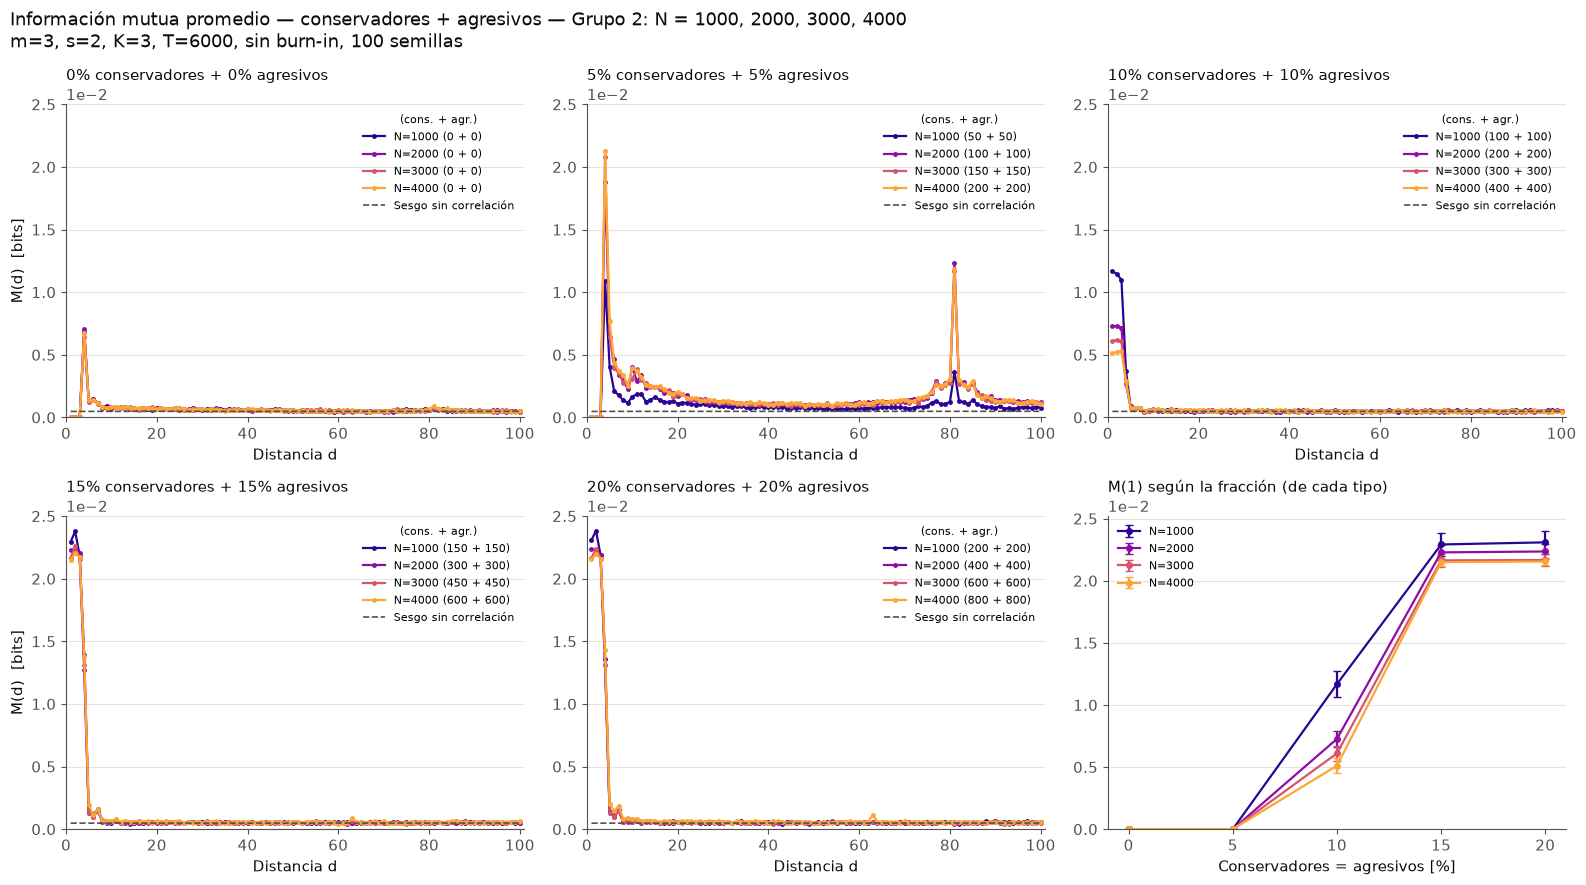

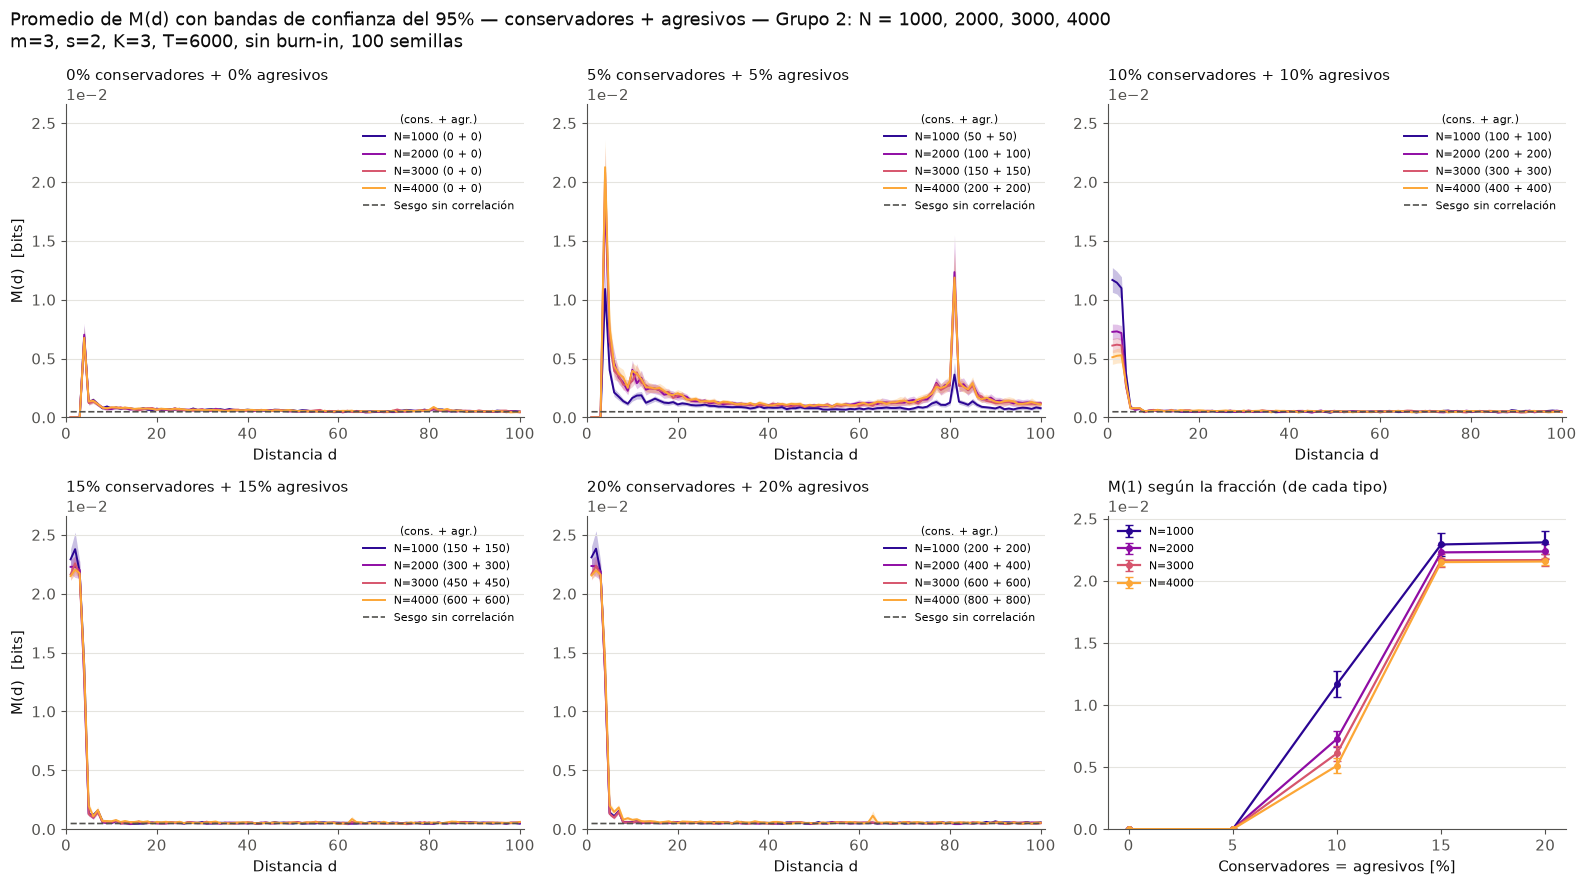

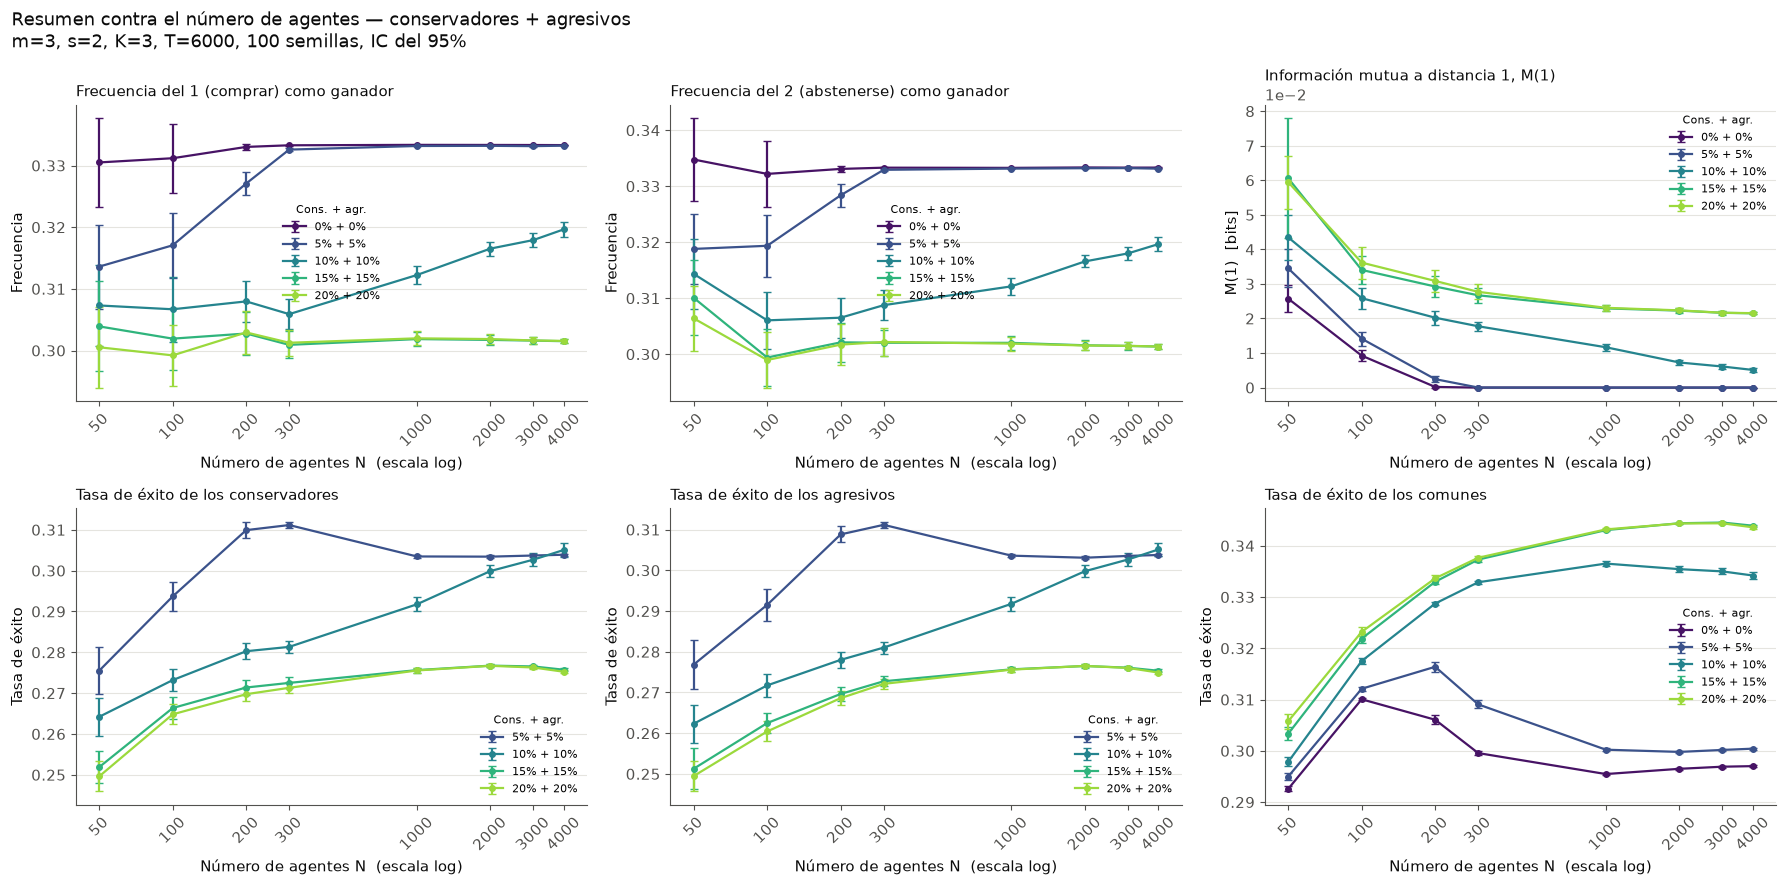


Tiempo total: 6.7 min


In [1]:
"""
Minority Game con abstencion - PASO 3d: CONSERVADORES + AGRESIVOS VARIANDO N
===========================================================================
Tesis: Complejidad e informacion en un minority game con opcion de abstencion
Base: R. Mansilla, Phys. Rev. E 62, 4553 (2000), Ec. (6)

Alfabeto: 0 = vender, 1 = comprar, 2 = abstenerse (mantener)

Caso 3 (2 estrategias CON puntaje) con TRES tipos de agentes:

  * CONSERVADORES: en sus 2 tablas de estrategias, toda historia con
    MAS DE UN "2" responde siempre 2 (mantener).
    Con m = 3: 022, 122, 202, 212, 220, 221, 222
  * AGRESIVOS: la misma regla, pero con el 1. Toda historia con
    MAS DE UN "1" responde siempre 1 (comprar).
    Con m = 3: 011, 101, 110, 111, 112, 121, 211
  * COMUNES: el resto, con estrategias aleatorias como en el Caso 3.

En las historias donde no aplica su regla, conservadores y agresivos
tienen estrategias aleatorias como cualquier agente, y todas se
califican con el mismo puntaje. Las dos listas de historias no se
enciman (con m = 3 no cabe tener dos "1" y dos "2" a la vez).

LA MISMA FRACCION PARA LOS DOS TIPOS: con 10% habra 10% de
conservadores Y 10% de agresivos (20% de agentes especiales en total).

    Grupo 1: N = 50, 100, 200, 300
    Grupo 2: N = 1000, 2000, 3000, 4000
    Fracciones: 0%, 5%, 10%, 15%, 20% (de cada tipo), 100 semillas

Como se eligen los agentes de cada tipo: con un generador aparte se
hace una permutacion de los N agentes. Los conservadores son los
PRIMEROS de esa lista (los mismos agentes que en el codigo de solo
conservadores) y los agresivos son los ULTIMOS (los mismos que en el
codigo de solo agresivos). Asi los dos grupos nunca se enciman y los
resultados se pueden comparar con los otros dos codigos.

Las cadenas se reparten entre los nucleos del procesador con joblib.
Los resultados son identicos a correrlo con un solo nucleo.
"""

import os
import time
import numpy as np
import matplotlib.pyplot as plt

try:
    from scipy.stats import t as t_student
except ImportError:
    t_student = None
T_95 = 1.984  # t de Student, 95%, 99 g.l. (por si no hay scipy)

try:
    from joblib import Parallel, delayed
    HAY_JOBLIB = True
except ImportError:
    HAY_JOBLIB = False


# #####################################################################
# #####################################################################
# ##                                                                 ##
# ##   >>>>>>>>>  OPCION: DESCARGAR O NO DESCARGAR  <<<<<<<<<        ##
# ##                                                                 ##
# ##   Las graficas SIEMPRE se muestran en el notebook.              ##
# ##                                                                 ##
# ##   DESCARGAR_GRAFICAS = True   -> ademas se guardan como .png    ##
# ##                                  en CARPETA_SALIDA y, si estas  ##
# ##                                  en Google Colab, se descarga   ##
# ##                                  un .zip con todas.             ##
# ##   DESCARGAR_GRAFICAS = False  -> solo se ven, no se guarda nada ##
# ##                                                                 ##
# ##   GUARDAR_CSV: lo mismo, pero para las tablas de resultados.    ##
# ##                                                                 ##
# #####################################################################
DESCARGAR_GRAFICAS = False      # <-- CAMBIA AQUI: True o False
GUARDAR_CSV        = False      # <-- CAMBIA AQUI: True o False
CARPETA_SALIDA     = "resultados_conservadores_agresivos_N"
# #####################################################################
# #####################################################################


# =====================================================================
# NUCLEOS DEL PROCESADOR
# =====================================================================
#   -1 -> usa TODOS los nucleos
#   -2 -> usa todos menos uno (la computadora queda mas libre mientras corre)
#    1 -> un solo nucleo
N_NUCLEOS = -1


# =====================================================================
# PARAMETROS COMUNES (iguales a los codigos anteriores)
# =====================================================================
SEMILLA_MAESTRA = 1907443528
N_CADENAS = 100

M       = 3      # memoria
K       = 3      # alfabeto
S       = 2      # estrategias por agente
T       = 6000   # ciclos por partida (sin burn-in)

D_MAX   = 100
NIVEL   = 0.95

GRUPOS = [
    ("grupo1", [50, 100, 200, 300]),
    ("grupo2", [1000, 2000, 3000, 4000]),
]


# =====================================================================
# PARAMETROS DE LOS AGENTES ESPECIALES
# =====================================================================
# Fraccion de CADA tipo. Con 0.10 hay 10% conservadores + 10% agresivos.
FRACCIONES = [0.00, 0.05, 0.10, 0.15, 0.20]   # 0% = referencia (Caso 3)

ACCION_CONSERVADORA = 2   # mantener, cuando hay mas de un 2
ACCION_AGRESIVA     = 1   # comprar,  cuando hay mas de un 1
MIN_REPETICIONES    = 2   # "mas de un"  ->  al menos 2 en la historia

# Generador aparte para elegir quien es de cada tipo (la misma semilla
# que en el codigo de conservadores, para que sean los mismos agentes).
SEMILLA_TIPOS = 2024


def numero_de_agentes(fraccion, N):
    """Cuantos agentes de UN tipo (redondeo hacia arriba en .5).

    Solo importa con N = 50: 5% -> 3 agentes, 15% -> 8 agentes.
    """
    return int(np.floor(fraccion * N + 0.5))


def historias_con_simbolo(m, K, simbolo, min_veces):
    """Indices de las historias donde 'simbolo' aparece al menos min_veces."""
    indices, etiquetas = [], []
    for h in range(K ** m):
        digitos = [(h // K ** (m - 1 - p)) % K for p in range(m)]
        if digitos.count(simbolo) >= min_veces:
            indices.append(h)
            etiquetas.append("".join(str(x) for x in digitos))
    return np.array(indices, dtype=int), etiquetas


# =====================================================================
# REGLA DE GANADOR (identica)
# =====================================================================
def regla_ganador(conteos, rng):
    """Gana el argmin sobre las K acciones, con desempate aleatorio."""
    empatados = np.flatnonzero(conteos == conteos.min())
    return int(rng.choice(empatados))


# =====================================================================
# SIMULACION: CASO 3 + CONSERVADORES + AGRESIVOS
# =====================================================================
def simular_con_tipos(N, m, s, K, T, n_cons, n_agr, h_cons, h_agr, semilla,
                      accion_cons, accion_agr, semilla_tipos):
    """Caso 3 con n_cons conservadores y n_agr agresivos.

    Devuelve:
      serie_ganadores : cadena de ganadores (longitud T)
      exitos_agente   : cuantas veces acerto cada agente
      es_cons, es_agr : mascaras booleanas de cada tipo
      ciclos_hc       : ciclos en que la historia tenia mas de un 2
      ciclos_ha       : ciclos en que la historia tenia mas de un 1
    """
    if n_cons + n_agr > N:
        raise ValueError("Hay mas agentes especiales que agentes en total")

    rng = np.random.default_rng(semilla)
    N_HIST = K ** m

    # --- estrategias (igual que el Caso 3) ---
    estrategias = rng.integers(0, K, size=(N, s, N_HIST))

    # --- elegir a los agentes de cada tipo (generador aparte) ---
    rng_tipos = np.random.default_rng([semilla, semilla_tipos])
    orden = rng_tipos.permutation(N)
    es_cons = np.zeros(N, dtype=bool)
    es_agr = np.zeros(N, dtype=bool)
    es_cons[orden[:n_cons]] = True               # los primeros
    if n_agr > 0:
        es_agr[orden[N - n_agr:]] = True         # los ultimos

    # --- reglas fijas en AMBAS tablas de estrategias ---
    if n_cons > 0:
        estrategias[np.ix_(es_cons, np.arange(s), h_cons)] = accion_cons
    if n_agr > 0:
        estrategias[np.ix_(es_agr, np.arange(s), h_agr)] = accion_agr

    puntajes = np.zeros((N, s))
    historia = rng.integers(0, K, size=m)
    pesos = K ** np.arange(m - 1, -1, -1)
    indices = np.arange(N)

    es_hist_cons = np.zeros(N_HIST, dtype=bool)
    es_hist_cons[h_cons] = True
    es_hist_agr = np.zeros(N_HIST, dtype=bool)
    es_hist_agr[h_agr] = True

    serie_ganadores = np.zeros(T, dtype=int)
    exitos_agente = np.zeros(N, dtype=int)
    ciclos_hc = 0
    ciclos_ha = 0

    for t in range(T):
        idx = int(historia @ pesos)                                  # 1
        ciclos_hc += es_hist_cons[idx]
        ciclos_ha += es_hist_agr[idx]
        mejor = np.argmax(puntajes + rng.random((N, s)) * 0.5, axis=1)  # 2
        acciones = estrategias[indices, mejor, idx]                  # 3
        conteos = np.bincount(acciones, minlength=K)                 # 4
        ganador = regla_ganador(conteos, rng)                        # 5
        puntajes += (estrategias[:, :, idx] == ganador)              # 6
        serie_ganadores[t] = ganador                                 # 7
        exitos_agente += (acciones == ganador)
        historia = np.roll(historia, -1)                             # 8
        historia[-1] = ganador

    return (serie_ganadores, exitos_agente, es_cons, es_agr,
            ciclos_hc, ciclos_ha)


# =====================================================================
# FUNCION DE INFORMACION MUTUA - Ec. (6) del PRE 62 (identica)
# =====================================================================
def informacion_mutua(serie, d, K):
    """M(d) = sum_{a,b} P_ab(d) * log2[ P_ab(d) / (P_a * P_b) ]"""
    x = serie[:-d]
    y = serie[d:]
    n_pares = len(x)
    conjunta = np.bincount(x * K + y, minlength=K * K).reshape(K, K) / n_pares
    densidad = np.bincount(serie, minlength=K) / len(serie)
    producto = np.outer(densidad, densidad)
    M_d = 0.0
    for a in range(K):
        for b in range(K):
            if conjunta[a, b] > 0:
                M_d += conjunta[a, b] * np.log2(conjunta[a, b] / producto[a, b])
    return M_d


def sesgo_esperado(K, n_pares):
    """Valor esperado de M(d) en una cadena sin correlacion (tamano finito)."""
    return (K - 1) ** 2 / (2 * n_pares * np.log(2))


# =====================================================================
# UNA CADENA COMPLETA  (la tarea que se reparte entre nucleos)
# =====================================================================
def tasa(exitos, mascara, T):
    """Tasa de exito media de un grupo de agentes (NaN si esta vacio)."""
    n = mascara.sum()
    return exitos[mascara].sum() / (n * T) if n > 0 else np.nan


def correr_cadena(N, n_cons, n_agr, semilla, m, s, K, T, d_max, h_cons,
                  h_agr, accion_cons, accion_agr, semilla_tipos):
    serie, exitos, es_cons, es_agr, ciclos_hc, ciclos_ha = simular_con_tipos(
        N, m, s, K, T, n_cons, n_agr, h_cons, h_agr, semilla,
        accion_cons, accion_agr, semilla_tipos)

    Md = np.array([informacion_mutua(serie, d, K)
                   for d in range(1, d_max + 1)])
    es_com = ~(es_cons | es_agr)
    return {
        "Md": Md,
        "frec": np.bincount(serie, minlength=K) / T,
        "exito_total": exitos.sum() / (N * T),
        "exito_cons": tasa(exitos, es_cons, T),
        "exito_agr": tasa(exitos, es_agr, T),
        "exito_com": tasa(exitos, es_com, T),
        "frac_hc": ciclos_hc / T,
        "frac_ha": ciclos_ha / T,
    }


def ejecutar(tareas, h_cons, h_agr):
    """Corre una lista de tareas (N, n_cons, n_agr, semilla) en varios nucleos."""
    argumentos = dict(m=M, s=S, K=K, T=T, d_max=D_MAX, h_cons=h_cons,
                      h_agr=h_agr, accion_cons=ACCION_CONSERVADORA,
                      accion_agr=ACCION_AGRESIVA, semilla_tipos=SEMILLA_TIPOS)
    if HAY_JOBLIB and N_NUCLEOS != 1:
        return Parallel(n_jobs=N_NUCLEOS)(
            delayed(correr_cadena)(N, nc, na, sem, **argumentos)
            for N, nc, na, sem in tareas)
    return [correr_cadena(N, nc, na, sem, **argumentos)
            for N, nc, na, sem in tareas]


def resumir(bloque, t_crit):
    """Junta las 100 cadenas de un mismo (N, fraccion)."""
    tabla = np.array([b["Md"] for b in bloque])          # 100 x D_MAX
    media = tabla.mean(axis=0)
    desv = tabla.std(axis=0, ddof=1)
    error_est = desv / np.sqrt(len(bloque))
    r = {
        "tabla": tabla, "media": media, "desv": desv, "error_est": error_est,
        "ic_inf": media - t_crit * error_est,
        "ic_sup": media + t_crit * error_est,
        "frecuencias": np.array([b["frec"] for b in bloque]),
    }
    for clave in ("exito_total", "exito_cons", "exito_agr", "exito_com",
                  "frac_hc", "frac_ha"):
        r[clave] = np.array([b[clave] for b in bloque])
    return r


# =====================================================================
# UTILIDADES: estadistica, graficas y archivos
# =====================================================================
def media_e_ic(x, t_crit):
    """Media y semiancho del intervalo de confianza (ignora NaN)."""
    x = np.asarray(x, dtype=float)
    x = x[~np.isnan(x)]
    if len(x) < 2:
        return np.nan, np.nan
    return x.mean(), t_crit * x.std(ddof=1) / np.sqrt(len(x))


def media_o_nan(x):
    x = np.asarray(x, dtype=float)
    return np.nan if np.all(np.isnan(x)) else np.nanmean(x)


AZUL = "#2a78d6"
GRIS = "#52514e"
TINTA = "#0b0b0b"
REJILLA = "#e5e4df"
plt.rcParams.update({
    "font.size": 11,
    "axes.edgecolor": GRIS,
    "axes.labelcolor": TINTA,
    "xtick.color": GRIS,
    "ytick.color": GRIS,
    "axes.spines.top": False,
    "axes.spines.right": False,
})


def colores_N(lista_N):
    return plt.cm.plasma(np.linspace(0.05, 0.80, len(lista_N)))


def colores_fraccion():
    return plt.cm.viridis(np.linspace(0.05, 0.85, len(FRACCIONES)))


def mostrar_y_guardar(fig, nombre_archivo):
    """Muestra la figura en el notebook y, si se pidio, la guarda."""
    if DESCARGAR_GRAFICAS:
        fig.savefig(os.path.join(CARPETA_SALIDA, nombre_archivo),
                    dpi=200, bbox_inches="tight")
        print(f"  Guardado: {nombre_archivo}")
    plt.show()
    plt.close(fig)


def guardar_csv(nombre_archivo, datos, fmt, encabezado):
    if GUARDAR_CSV:
        np.savetxt(os.path.join(CARPETA_SALIDA, "csv", nombre_archivo), datos,
                   fmt=fmt, delimiter=",", header=encabezado, comments="# ")


def descargar_zip():
    """En Colab descarga un .zip con todo; fuera de Colab solo avisa."""
    try:
        from google.colab import files
    except ImportError:
        print(f"\nLos archivos quedaron en la carpeta '{CARPETA_SALIDA}'.")
        return
    import shutil
    archivo = shutil.make_archive(CARPETA_SALIDA, "zip", CARPETA_SALIDA)
    files.download(archivo)


def pct_de(fraccion):
    return int(round(100 * fraccion))


# =====================================================================
# GRAFICAS DE UN GRUPO DE N
# =====================================================================
def graficar_grupo(nombre_grupo, lista_N, resultados, distancias):
    """Dos figuras por grupo (promedios y bandas), un panel por fraccion.
    El ultimo panel muestra M(1) contra la fraccion."""
    cols = colores_N(lista_N)
    referencia = sesgo_esperado(K, T - distancias)
    numero = nombre_grupo[-1]

    for con_bandas in (False, True):
        fig, ejes = plt.subplots(2, 3, figsize=(16, 9))
        ejes = ejes.ravel()
        y_max = max(resultados[(N, f)]["ic_sup" if con_bandas else "media"].max()
                    for N in lista_N for f in FRACCIONES) * 1.05

        for p, fraccion in enumerate(FRACCIONES):
            ax = ejes[p]
            for N, col in zip(lista_N, cols):
                r = resultados[(N, fraccion)]
                n = numero_de_agentes(fraccion, N)
                etiqueta = f"N={N} ({n} + {n})"
                if con_bandas:
                    ax.fill_between(distancias, r["ic_inf"], r["ic_sup"],
                                    color=col, alpha=0.25, lw=0)
                    ax.plot(distancias, r["media"], color=col, lw=1.4,
                            label=etiqueta)
                else:
                    ax.plot(distancias, r["media"], color=col, lw=1.6,
                            marker="o", ms=2.5, label=etiqueta)
            ax.plot(distancias, referencia, color=GRIS, lw=1.2, ls="--",
                    label="Sesgo sin correlación")
            ax.set_title(f"{pct_de(fraccion)}% conservadores + "
                         f"{pct_de(fraccion)}% agresivos", loc="left",
                         color=TINTA, fontsize=11)
            ax.set_xlim(0, D_MAX + 1)
            ax.set_ylim(0, y_max)
            ax.grid(axis="y", color=REJILLA, lw=0.8)
            ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
            ax.set_xlabel("Distancia d")
            if p % 3 == 0:
                ax.set_ylabel("M(d)  [bits]")
            ax.legend(frameon=False, fontsize=8, loc="upper right",
                      title="(cons. + agr.)", title_fontsize=8)

        ax = ejes[5]
        pcts = [pct_de(f) for f in FRACCIONES]
        for N, col in zip(lista_N, cols):
            m1 = [resultados[(N, f)]["media"][0] for f in FRACCIONES]
            e1 = [resultados[(N, f)]["ic_sup"][0] - resultados[(N, f)]["media"][0]
                  for f in FRACCIONES]
            ax.errorbar(pcts, m1, yerr=e1, color=col, marker="o", ms=4,
                        capsize=3, lw=1.6, label=f"N={N}")
        ax.set_title("M(1) según la fracción (de cada tipo)", loc="left",
                     color=TINTA, fontsize=11)
        ax.set_xlabel("Conservadores = agresivos [%]")
        ax.set_xticks(pcts)
        ax.set_ylim(bottom=0)
        ax.grid(axis="y", color=REJILLA, lw=0.8)
        ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
        ax.legend(frameon=False, fontsize=8)

        tipo = ("Promedio de M(d) con bandas de confianza del "
                f"{int(NIVEL*100)}%" if con_bandas
                else "Información mutua promedio")
        fig.suptitle(f"{tipo} — conservadores + agresivos — Grupo {numero}: "
                     f"N = {', '.join(str(n) for n in lista_N)}\n"
                     f"m={M}, s={S}, K={K}, T={T}, sin burn-in, "
                     f"{N_CADENAS} semillas", x=0.01, ha="left",
                     color=TINTA, fontsize=13)
        fig.tight_layout()
        sufijo = "bandas" if con_bandas else "promedio"
        mostrar_y_guardar(fig, f"grafica_Md_cons_agr_{nombre_grupo}_{sufijo}.png")


# =====================================================================
# GRAFICA RESUMEN CONTRA N (todos los N juntos)
# =====================================================================
def graficar_resumen(todos_N, resultados, t_crit):
    cols = colores_fraccion()
    paneles = [
        ("Frecuencia del 1 (comprar) como ganador",
         lambda r: r["frecuencias"][:, 1], "Frecuencia"),
        ("Frecuencia del 2 (abstenerse) como ganador",
         lambda r: r["frecuencias"][:, 2], "Frecuencia"),
        ("Información mutua a distancia 1, M(1)",
         lambda r: r["tabla"][:, 0], "M(1)  [bits]"),
        ("Tasa de éxito de los conservadores",
         lambda r: r["exito_cons"], "Tasa de éxito"),
        ("Tasa de éxito de los agresivos",
         lambda r: r["exito_agr"], "Tasa de éxito"),
        ("Tasa de éxito de los comunes",
         lambda r: r["exito_com"], "Tasa de éxito"),
    ]

    fig, ejes = plt.subplots(2, 3, figsize=(18, 9))
    for ax, (titulo, extraer, ylabel) in zip(ejes.ravel(), paneles):
        for fraccion, col in zip(FRACCIONES, cols):
            m_ic = np.array([media_e_ic(extraer(resultados[(N, fraccion)]),
                                        t_crit) for N in todos_N])
            if np.all(np.isnan(m_ic[:, 0])):
                continue          # 0% no tiene agentes especiales
            ax.errorbar(todos_N, m_ic[:, 0], yerr=m_ic[:, 1], color=col,
                        marker="o", ms=4, capsize=3, lw=1.6,
                        label=f"{pct_de(fraccion)}% + {pct_de(fraccion)}%")
        ax.set_xscale("log")
        ax.set_xticks(todos_N)
        ax.set_xticklabels([str(n) for n in todos_N], rotation=45)
        ax.minorticks_off()
        ax.set_xlabel("Número de agentes N  (escala log)")
        ax.set_ylabel(ylabel)
        ax.set_title(titulo, loc="left", color=TINTA, fontsize=11)
        ax.grid(axis="y", color=REJILLA, lw=0.8)
        ax.legend(frameon=False, fontsize=8, title="Cons. + agr.",
                  title_fontsize=8)
    ejes[0, 2].ticklabel_format(axis="y", style="sci", scilimits=(0, 0))

    fig.suptitle("Resumen contra el número de agentes — conservadores + "
                 f"agresivos\nm={M}, s={S}, K={K}, T={T}, {N_CADENAS} "
                 f"semillas, IC del {int(NIVEL*100)}%", x=0.01, ha="left",
                 color=TINTA, fontsize=13)
    fig.tight_layout()
    mostrar_y_guardar(fig, "grafica_resumen_cons_agr_vs_N.png")


# =====================================================================
# PROGRAMA PRINCIPAL
# =====================================================================
if __name__ == "__main__":

    if DESCARGAR_GRAFICAS or GUARDAR_CSV:
        os.makedirs(os.path.join(CARPETA_SALIDA, "csv"), exist_ok=True)

    semillas = np.random.SeedSequence(SEMILLA_MAESTRA).generate_state(N_CADENAS)
    distancias = np.arange(1, D_MAX + 1)
    t_crit = (t_student.ppf(0.5 + NIVEL / 2, N_CADENAS - 1)
              if t_student is not None else T_95)
    h_cons, etiquetas_hc = historias_con_simbolo(M, K, 2, MIN_REPETICIONES)
    h_agr, etiquetas_ha = historias_con_simbolo(M, K, 1, MIN_REPETICIONES)

    if not HAY_JOBLIB:
        print("AVISO: joblib no esta instalado -> se usa un solo nucleo "
              "(pip install joblib)")
    print(f"Nucleos disponibles: {os.cpu_count()}   N_NUCLEOS = {N_NUCLEOS}")
    print(f"Conservadores eligen {ACCION_CONSERVADORA} en: "
          f"{', '.join(etiquetas_hc)}")
    print(f"Agresivos     eligen {ACCION_AGRESIVA} en: "
          f"{', '.join(etiquetas_ha)}")
    print(f"Fracciones (de cada tipo): {[f'{pct_de(f)}%' for f in FRACCIONES]}"
          f"   semillas por punto: {N_CADENAS}")

    resultados = {}
    inicio_total = time.time()

    for nombre_grupo, lista_N in GRUPOS:
        print("\n" + "=" * 112)
        print(f"  {nombre_grupo.upper()}: N = {lista_N}")
        print("=" * 112)

        for N in lista_N:
            tareas = [(N, numero_de_agentes(f, N), numero_de_agentes(f, N),
                       int(sem)) for f in FRACCIONES for sem in semillas]
            t0 = time.time()
            salida = ejecutar(tareas, h_cons, h_agr)

            for i, fraccion in enumerate(FRACCIONES):
                bloque = salida[i * N_CADENAS:(i + 1) * N_CADENAS]
                resultados[(N, fraccion)] = resumir(bloque, t_crit)

            print(f"\n  N = {N}  (alfa = {K**M}/{N} = {K**M / N:.4f})  "
                  f"listo en {time.time() - t0:.1f} s")
            print(f"    {'%':>4} {'c+a':>9} {'f(0)':>7} {'f(1)':>7} "
                  f"{'f(2)':>7} {'h>1dos':>7} {'h>1unos':>8} "
                  f"{'exito tot':>10} {'cons':>7} {'agr':>7} {'comunes':>8} "
                  f"{'M(1)':>10}")
            for fraccion in FRACCIONES:
                r = resultados[(N, fraccion)]
                f = r["frecuencias"].mean(axis=0)
                n = numero_de_agentes(fraccion, N)
                print(f"    {pct_de(fraccion):>4d} {f'{n}+{n}':>9} "
                      f"{f[0]:>7.4f} {f[1]:>7.4f} {f[2]:>7.4f} "
                      f"{r['frac_hc'].mean():>7.4f} {r['frac_ha'].mean():>8.4f} "
                      f"{r['exito_total'].mean():>10.4f} "
                      f"{media_o_nan(r['exito_cons']):>7.4f} "
                      f"{media_o_nan(r['exito_agr']):>7.4f} "
                      f"{r['exito_com'].mean():>8.4f} "
                      f"{r['media'][0]:>10.3e}")

        graficar_grupo(nombre_grupo, lista_N, resultados, distancias)

    todos_N = [N for _, lista in GRUPOS for N in lista]
    graficar_resumen(todos_N, resultados, t_crit)

    print(f"\nTiempo total: {(time.time() - inicio_total) / 60:.1f} min")

    # --- CSV ---
    if GUARDAR_CSV:
        referencia = sesgo_esperado(K, T - distancias)
        filas = []
        for N in todos_N:
            for fraccion in FRACCIONES:
                r = resultados[(N, fraccion)]
                n = numero_de_agentes(fraccion, N)
                etiqueta = f"N{N}_{pct_de(fraccion):02d}pct"
                parametros = (f"N={N} m={M} s={S} K={K} T={T} burn_in=0 "
                              f"conservadores={n} agresivos={n} "
                              f"({pct_de(fraccion)}% cada uno) "
                              f"cadenas={N_CADENAS} "
                              f"semilla_maestra={SEMILLA_MAESTRA}")
                guardar_csv(
                    f"Md_cons_agr_{etiqueta}_promedio.csv",
                    np.column_stack([distancias, r["media"], r["desv"],
                                     r["error_est"], r["ic_inf"],
                                     r["ic_sup"], referencia]),
                    ["%d"] + ["%.8e"] * 6,
                    f"M(d) con conservadores y agresivos, Ec. (6) PRE 62\n"
                    f"{parametros}\nd,media,desv_estandar,error_estandar,"
                    f"ic_inferior,ic_superior,sesgo_esperado")
                guardar_csv(
                    f"Md_cons_agr_{etiqueta}_todas_las_cadenas.csv",
                    np.column_stack([semillas.astype(np.int64), r["tabla"]]),
                    ["%d"] + ["%.8e"] * D_MAX,
                    f"M(d) de cada cadena. Fila = una semilla, columna = d\n"
                    f"{parametros}\n"
                    f"semilla," + ",".join(f"d{d}" for d in distancias))
                f = r["frecuencias"].mean(axis=0)
                filas.append([N, pct_de(fraccion), n, n, f[0], f[1], f[2],
                              r["frac_hc"].mean(), r["frac_ha"].mean(),
                              r["exito_total"].mean(),
                              media_o_nan(r["exito_cons"]),
                              media_o_nan(r["exito_agr"]),
                              r["exito_com"].mean(),
                              r["media"][0], r["media"].mean()])
        guardar_csv(
            "resumen_cons_agr_vs_N.csv", np.array(filas, dtype=float),
            ["%d"] * 4 + ["%.6f"] * 9 + ["%.6e", "%.6e"],
            f"Resumen por N y fraccion (de cada tipo). m={M} s={S} K={K} "
            f"T={T} cadenas={N_CADENAS}\n"
            "N,porcentaje,n_conservadores,n_agresivos,frec_0,frec_1,frec_2,"
            "frac_historias_mas_de_un_2,frac_historias_mas_de_un_1,"
            "exito_todos,exito_conservadores,exito_agresivos,exito_comunes,"
            "M1,media_global_Md")
        print(f"CSV guardados en '{os.path.join(CARPETA_SALIDA, 'csv')}'")

    if DESCARGAR_GRAFICAS or GUARDAR_CSV:
        descargar_zip()